In [6]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 10.8 MB/s eta 0:00:00


In [10]:
import os, glob
zips = glob.glob('/content/*.zip')
print('Found zip:', zips)
!unzip -q -o "{zips[0]}" -d /content/raw
!ls /content/raw

Found zip: ['/content/archive.zip']
annotated-images  README.md  splits.json


In [11]:
import os, shutil, random
import xml.etree.ElementTree as ET

random.seed(42)
RAW = '/content/raw/annotated-images'
OUT = '/content/dataset'

if os.path.exists(OUT):
    shutil.rmtree(OUT)
for s in ['train', 'valid', 'test']:
    os.makedirs(f'{OUT}/{s}/images')
    os.makedirs(f'{OUT}/{s}/labels')

def xml_to_yolo(xml_path):
    root = ET.parse(xml_path).getroot()
    w = float(root.find('size/width').text)
    h = float(root.find('size/height').text)
    lines = []
    for obj in root.findall('object'):
        b = obj.find('bndbox')
        xmin, ymin = float(b.find('xmin').text), float(b.find('ymin').text)
        xmax, ymax = float(b.find('xmax').text), float(b.find('ymax').text)
        xc = ((xmin + xmax) / 2) / w
        yc = ((ymin + ymax) / 2) / h
        bw = (xmax - xmin) / w
        bh = (ymax - ymin) / h
        lines.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
    return lines, root.find('filename').text

pairs = []
for x in sorted(os.listdir(RAW)):
    if x.endswith('.xml'):
        lines, img_name = xml_to_yolo(f'{RAW}/{x}')
        if os.path.exists(f'{RAW}/{img_name}'):
            pairs.append((img_name, lines))

random.shuffle(pairs)
n = len(pairs)
n_train, n_val = int(n * 0.7), int(n * 0.2)
splits = {
    'train': pairs[:n_train],
    'valid': pairs[n_train:n_train + n_val],
    'test':  pairs[n_train + n_val:],
}

for name, items in splits.items():
    for img_name, lines in items:
        shutil.copy(f'{RAW}/{img_name}', f'{OUT}/{name}/images/{img_name}')
        with open(f'{OUT}/{name}/labels/{os.path.splitext(img_name)[0]}.txt', 'w') as f:
            f.write('\n'.join(lines) + '\n')
    print(name, len(items), 'images')
print('Total:', n)

train 465 images
valid 133 images
test 67 images
Total: 665


In [12]:
data_yaml = '''path: /content/dataset
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']
'''
with open('/content/dataset/data.yaml', 'w') as f:
    f.write(data_yaml)
print(open('/content/dataset/data.yaml').read())

path: /content/dataset
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']



In [13]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    project='/content/runs',
    name='pothole',
    exist_ok=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pothole, nbs=64, nms=None, opset=None, optimize=False, optimizer

In [14]:
best = YOLO('/content/runs/pothole/weights/best.pt')
m = best.val(data='/content/dataset/data.yaml', split='test')
print('Precision :', m.box.mp)
print('Recall    :', m.box.mr)
print('mAP@50    :', m.box.map50)
print('mAP@50-95 :', m.box.map)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1421.0±750.6 MB/s, size: 54.5 KB)
val: Scanning /content/dataset/test/labels... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 2.0Kit/s 0.0s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.5it/s 3.3s
                   all         67        159      0.792       0.74      0.779      0.511
Speed: 13.6ms preprocess, 13.1ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to /content/runs/detect/val
Precision : 0.791523871736649
Recall    : 0.7402484113484649
mAP@50    : 0.7789055942086005
mAP@50-95 : 0.511328439621922


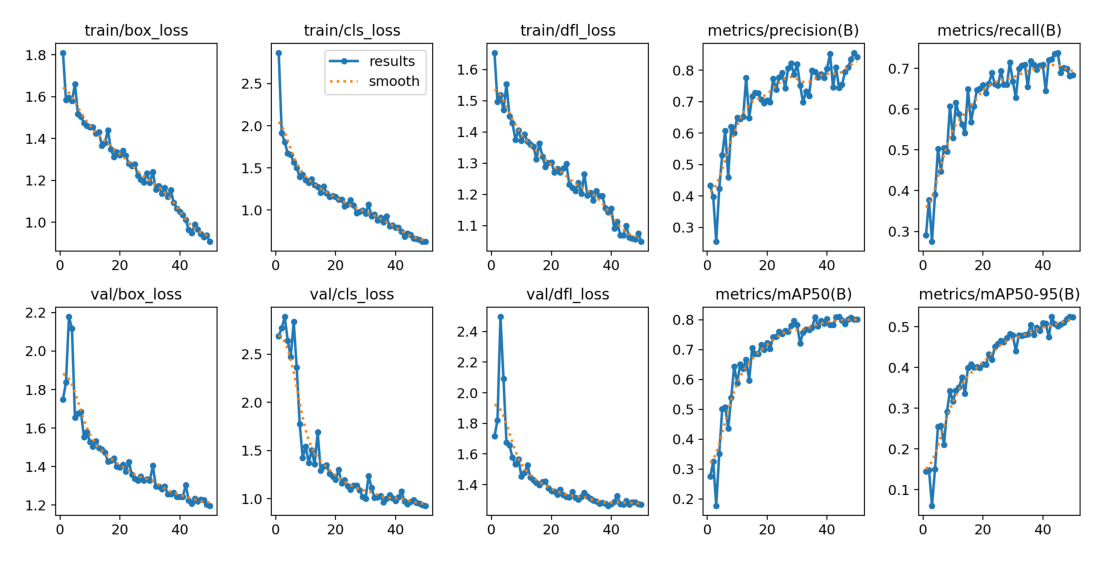

In [15]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread('/content/runs/pothole/results.png')
plt.figure(figsize=(14, 8)); plt.imshow(img); plt.axis('off'); plt.show()


0: 640x640 3 potholes, 7.4ms
1: 640x640 3 potholes, 7.4ms
2: 640x640 1 pothole, 7.4ms
3: 640x640 2 potholes, 7.4ms
4: 640x640 2 potholes, 7.4ms
5: 640x640 1 pothole, 7.4ms
Speed: 2.1ms preprocess, 7.4ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/predict


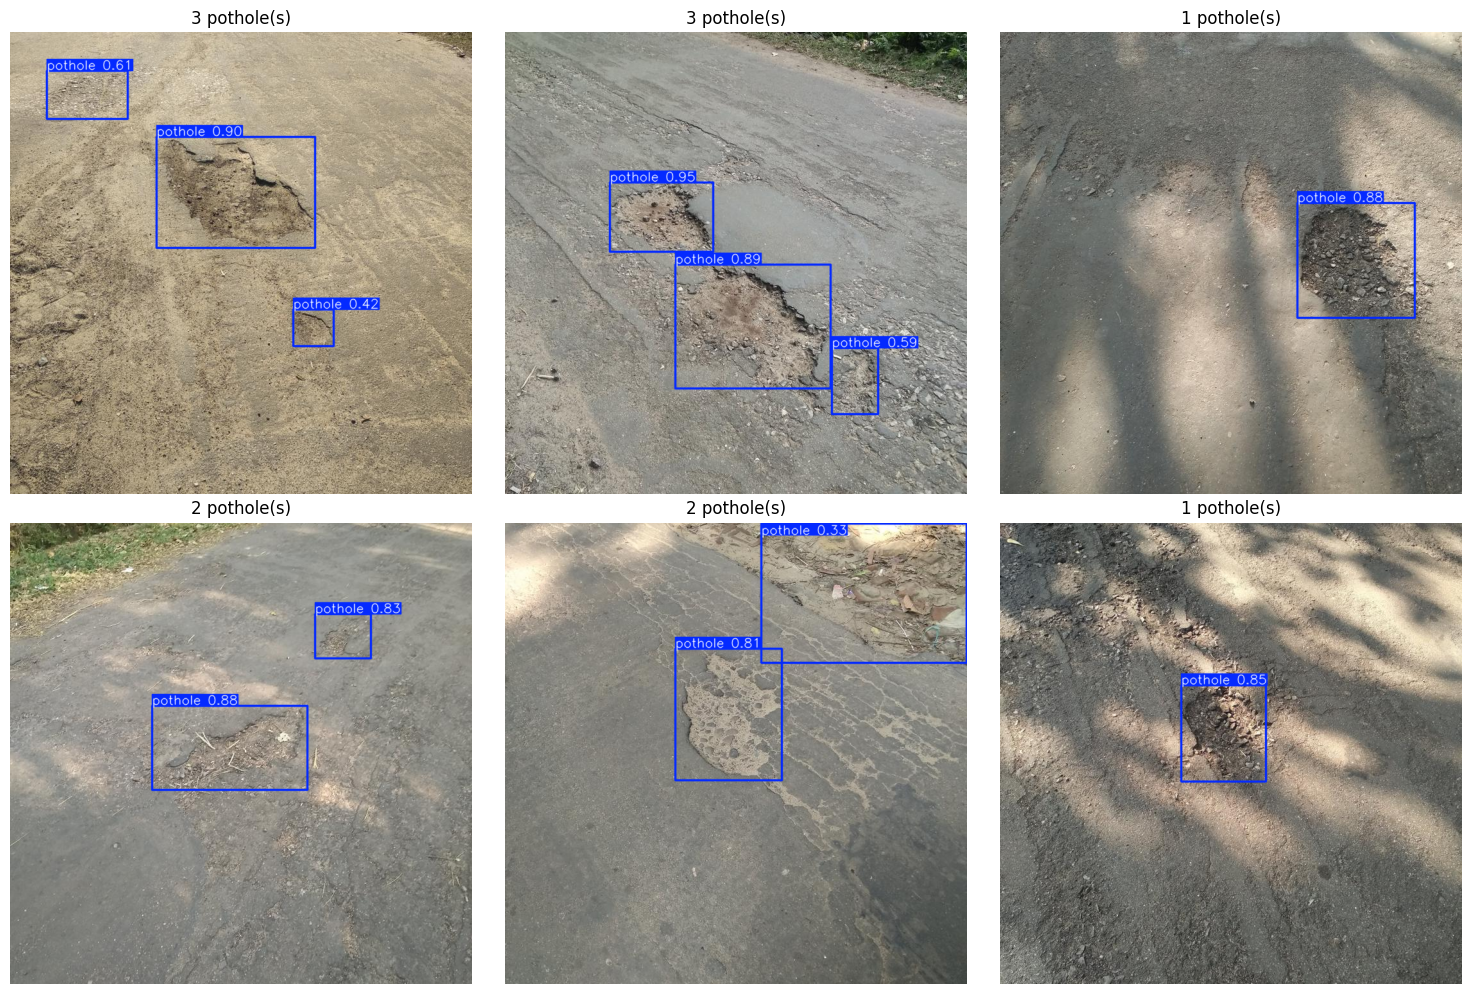

In [16]:
import glob, cv2
import matplotlib.pyplot as plt

test_imgs = sorted(glob.glob('/content/dataset/test/images/*'))[:6]
preds = best.predict(source=test_imgs, imgsz=640, conf=0.25, save=True,
                     project='/content/runs', name='predict', exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{len(r.boxes)} pothole(s)')
    ax.axis('off')
plt.tight_layout(); plt.show()


image 1/1 /content/img-101.jpg: 640x640 2 potholes, 13.4ms
Speed: 2.3ms preprocess, 13.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


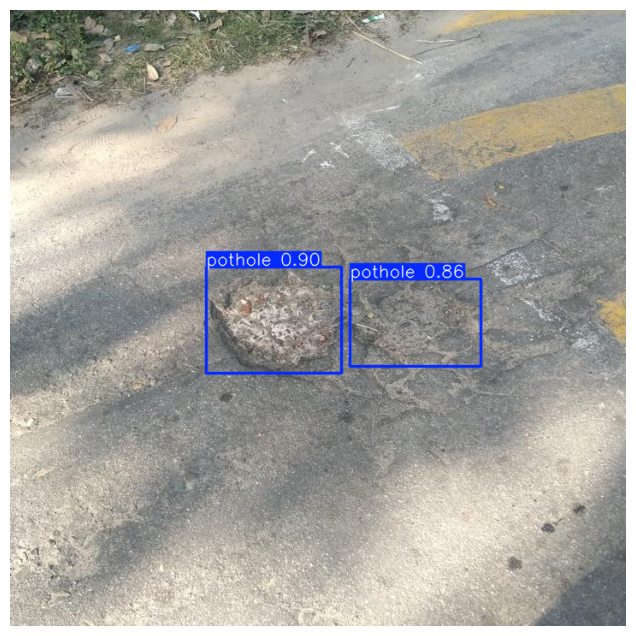

confidence: 0.9 box: [230, 301, 388, 425]
confidence: 0.86 box: [398, 315, 550, 417]


In [19]:
my_image = '/content/img-101.jpg'   # <- change this

if os.path.exists(my_image):
    r = best.predict(source=my_image, imgsz=640, conf=0.25)[0]
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
    for b in r.boxes:
        print('confidence:', round(float(b.conf), 2), 'box:', [round(v) for v in b.xyxy[0].tolist()])
else:
    print('Upload your image first and update the file name.')

In [21]:
from google.colab import files
files.download('/content/runs/pothole/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>